# Análise Exploratória dos Dados

---



In [ ]:
# Visualização, manipulação dados
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
import numpy as np, pandas as pd
pd.set_option('display.max_rows', None, 
              'display.max_columns', None, 
              'display.max_colwidth', None)

# Modelos Baseline
from sklearn.impute import SimpleImputer
from sklearn.naive_bayes import GaussianNB
from sklearn.decomposition import PCA

In [ ]:
df = pd.read_csv('../data/raw/cs-training.csv',
                 index_col=0)

credit_df = df.copy()
credit_df.head(1)

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0


In [37]:
# MonthlyIncome, NumberOfDependents estão faltando dados
credit_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 1 to 150000
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 non-null  float64
dtypes: float64(

In [74]:
# TODO: Imputar a mediana é realmente a melhor estratégia?
impute = SimpleImputer(strategy='median')

MonthlyIncome = np.array(credit_df.MonthlyIncome)[:, np.newaxis]
NumberOfDependents = np.array(credit_df.NumberOfDependents)[:, np.newaxis]
credit_df['MonthlyIncome'] = impute.fit_transform(MonthlyIncome).reshape(-1)
credit_df['NumberOfDependents'] = impute.fit_transform(NumberOfDependents).reshape(-1)

In [75]:
# age.min é zero (possível erro)
# NumberOfDependents.max é 20 (viável, mas improvável)
credit_df.describe()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,log_MonthlyIncome
count,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,1.500000e+05,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000
mean,0.066840,6.048438,52.295207,0.421033,353.005076,6.418455e+03,8.452760,0.265973,1.018240,0.240387,0.737413,8.447405
std,0.249746,249.755371,14.771866,4.192781,2037.818523,1.289040e+04,5.145951,4.169304,1.129771,4.155179,1.107021,1.195796
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.029867,41.000000,0.000000,0.175074,3.903000e+03,5.000000,0.000000,0.000000,0.000000,0.000000,8.269757
50%,0.000000,0.154181,52.000000,0.000000,0.366508,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000,8.594339
75%,0.000000,0.559046,63.000000,0.000000,0.868254,7.400000e+03,11.000000,0.000000,2.000000,0.000000,1.000000,8.909370
max,1.000000,50708.000000,109.000000,98.000000,329664.000000,3.008750e+06,58.000000,98.000000,54.000000,98.000000,20.000000,14.917036


### age

In [70]:
credit_df.age.value_counts().sort_index()

age
0         1
21      183
22      434
23      641
24      816
25      953
26     1193
27     1338
28     1560
29     1702
30     1937
31     2038
32     2050
33     2239
34     2155
35     2246
36     2379
37     2521
38     2631
39     2987
40     3093
41     3122
42     3082
43     3208
44     3294
45     3502
46     3714
47     3719
48     3806
49     3837
50     3753
51     3627
52     3609
53     3648
54     3561
55     3416
56     3589
57     3375
58     3443
59     3280
60     3258
61     3522
62     3568
63     3719
64     3058
65     2594
66     2494
67     2503
68     2235
69     1954
70     1777
71     1646
72     1649
73     1520
74     1451
75     1241
76     1183
77     1099
78     1054
79      981
80      876
81      774
82      647
83      512
84      480
85      483
86      407
87      357
88      313
89      276
90      198
91      154
92       93
93       87
94       47
95       45
96       18
97       17
98        6
99        9
101       3
102       3
103       3


In [72]:
credit_df.query('age == 0')

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,log_MonthlyIncome
65696,0,1.0,0,1,0.436927,6000.0,6,0,2,0,2.0,8.699681


### NumberOfTime30-59DaysPastDueNotWorse

In [77]:
credit_df['NumberOfTime30-59DaysPastDueNotWorse'].value_counts()

NumberOfTime30-59DaysPastDueNotWorse
0     126018
1      16033
2       4598
3       1754
4        747
5        342
98       264
6        140
7         54
8         25
9         12
96         5
10         4
12         2
13         1
11         1
Name: count, dtype: int64

### MonthlyIncome

In [51]:
credit_df['log_MonthlyIncome'] = np.log1p(credit_df.MonthlyIncome)

### Análise Gráfica

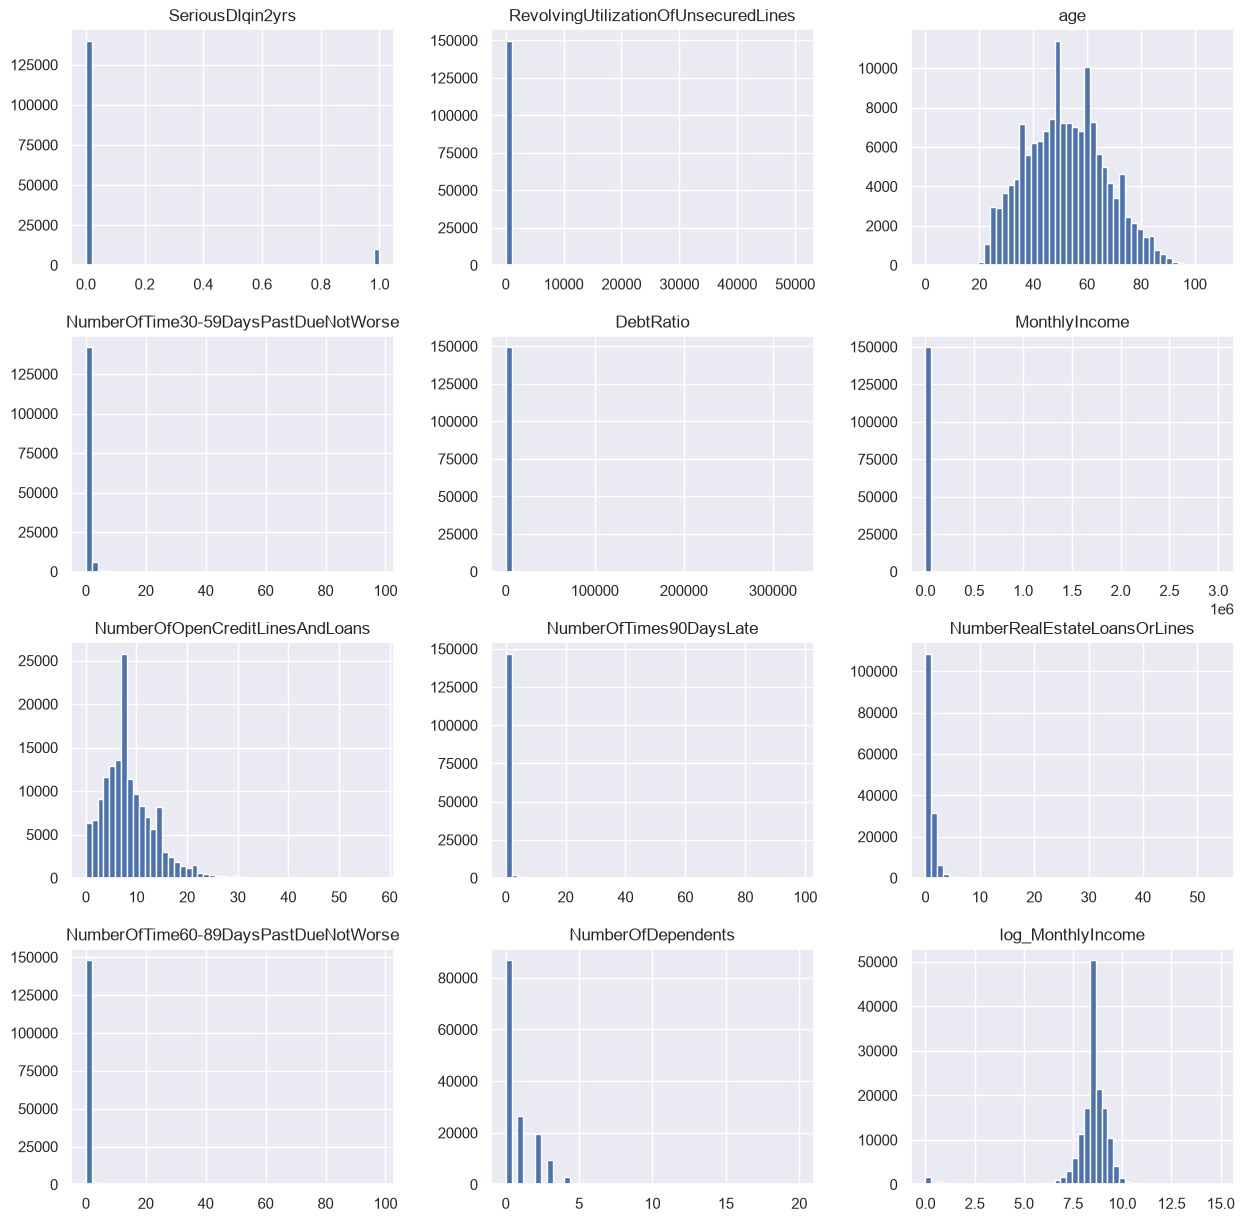

In [52]:
# Muitas features com classes bem desbalanceadas
# 'RevolvingUtilizationOfUnsecuredLines', 'NumberOfTime30-59DaysPastDueNotWorse', 
# 'DebtRatio', 'MonthlyIncome', 'NumberOfTimes90DaysLate', 'NumberOfTime60-89DaysPastDueNotWorse'
credit_df.hist(bins=50, figsize=(15, 15));

In [32]:
corr_matrix = credit_df.corr()
corr_matrix['SeriousDlqin2yrs'].abs().sort_values(ascending=False)

SeriousDlqin2yrs                        1.000000
NumberOfTime30-59DaysPastDueNotWorse    0.125587
NumberOfTimes90DaysLate                 0.117175
age                                     0.115386
NumberOfTime60-89DaysPastDueNotWorse    0.102261
NumberOfDependents                      0.046048
log_MonthlyIncome                       0.039615
NumberOfOpenCreditLinesAndLoans         0.029669
MonthlyIncome                           0.019746
DebtRatio                               0.007602
NumberRealEstateLoansOrLines            0.007038
RevolvingUtilizationOfUnsecuredLines    0.001802
Name: SeriousDlqin2yrs, dtype: float64

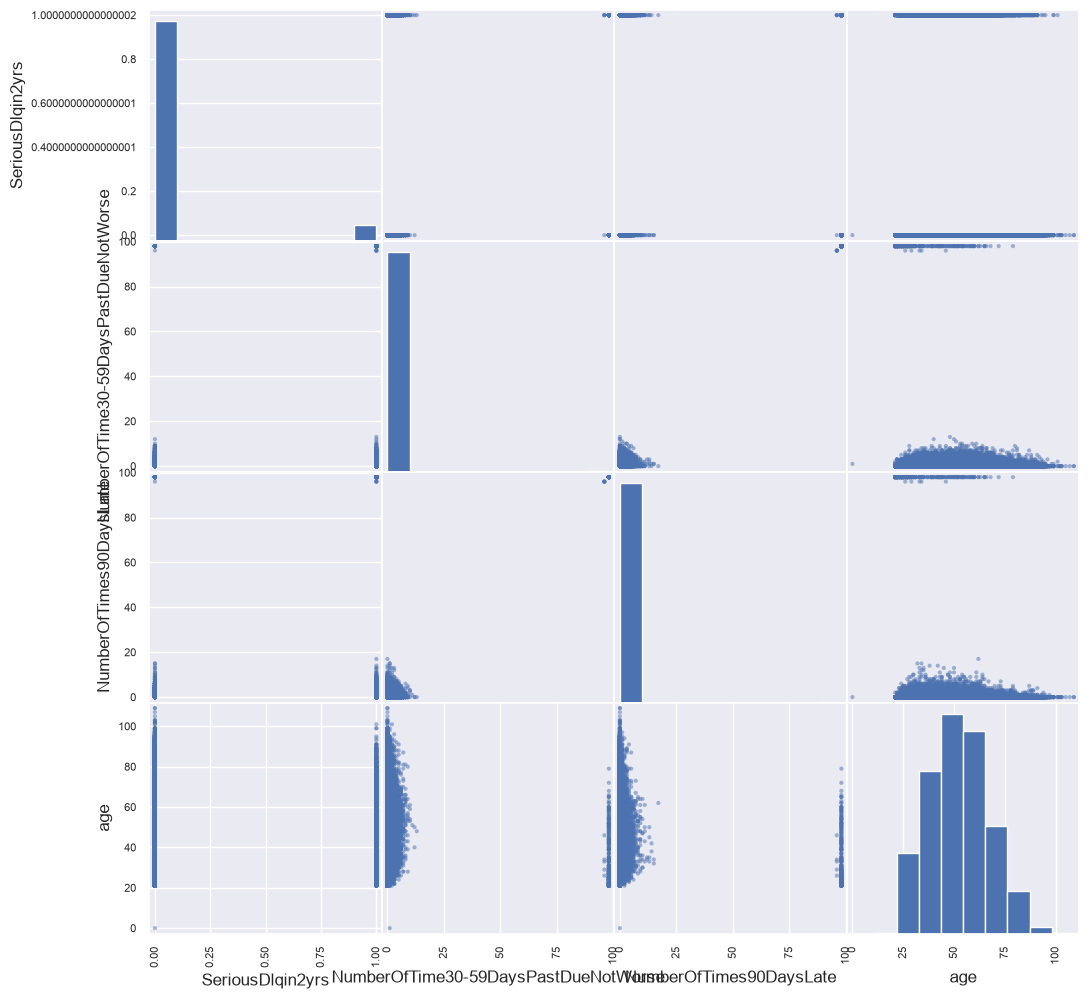

In [24]:
from pandas.plotting import scatter_matrix

features = ['SeriousDlqin2yrs',
            'NumberOfTime30-59DaysPastDueNotWorse',
            'NumberOfTimes90DaysLate',
            'age']

scatter_matrix(credit_df[features], figsize=(12, 12));

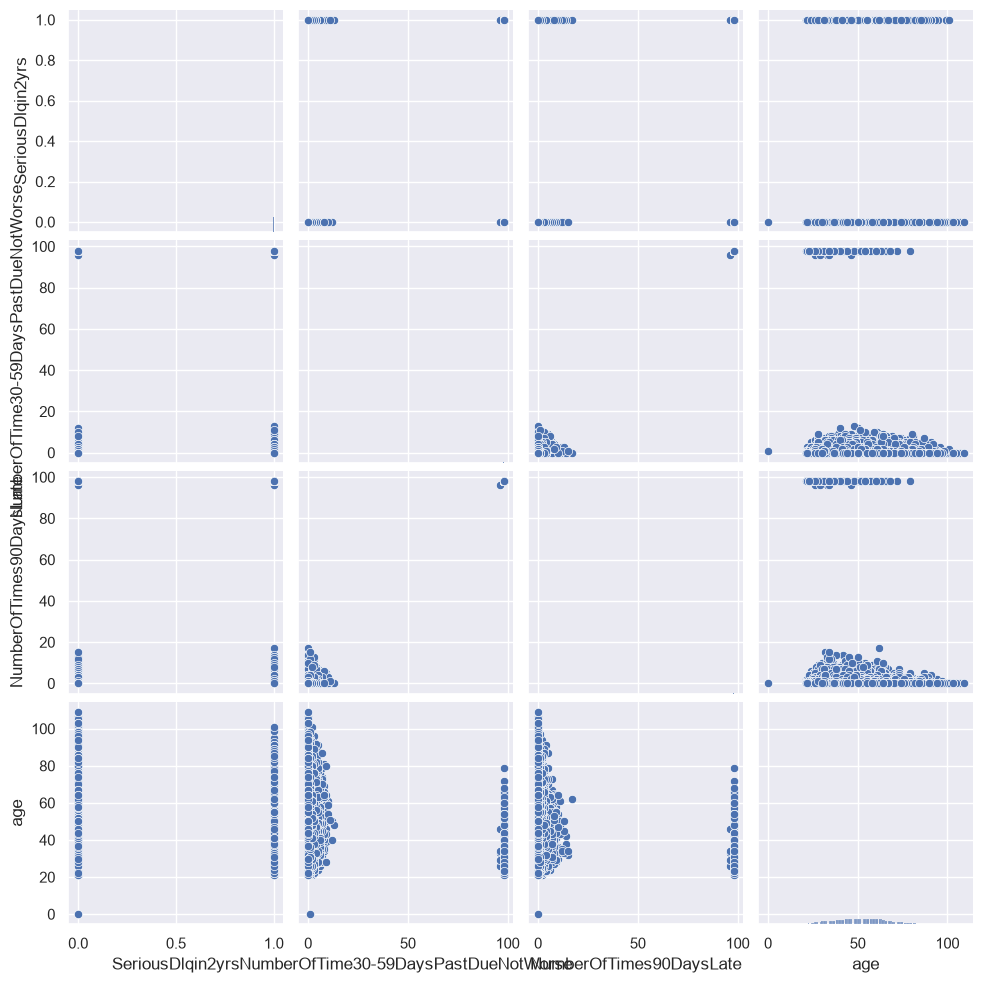

In [71]:
sns.pairplot(credit_df[features])

### Conclusões

Escrever em texto aqui